# Что реально двигает спрос на Airbnb: анализ по 10 городам мира

У хоста нет кнопки "сделать объявление популярнее", но есть набор решений, которые он
контролирует сам: цена, мгновенное бронирование, скорость ответа гостям, статус суперхоста, набор
удобств. Вопрос этого ноутбука простой — что из этого реально связано со спросом, а что просто
кажется важным.

Датасет с Airbnb с Kaggle разобран, наверное, тысячу раз, и почти все решения по нему —
это десяток графиков распределения цены и пара слов про Нью-Йорк. Я попробовала копнуть туда, куда
обычно не доходят руки: в `Reviews.csv` нет данных о бронированиях, значит proxy для спроса нужно
сначала обосновать и проверить на искажения (там реально нашёлся COVID-провал в 2020 году и ловушка
с возрастом объявлений). Цены даны "в валюте каждой страны" без курса, то есть сравнивать их между
городами напрямую — ошибка. Модель строится не как "накорреляли что попало", а с проверкой
мультиколлинеарности, устойчивыми ошибками и сравнением двух разных подходов к счётным данным.
Отдельно проверяю, не прячет ли общая модель разную картину по отдельным городам. И в конце честно
разделяю, где у меня корреляция, а где может быть причинность — статус суперхоста, например, во
многом сам является следствием высокого числа отзывов, а не только их причиной.

Структура:
1. Данные и их ограничения
2. Proxy спроса из Reviews.csv (и почему это не тривиально)
3. Чистка Listings.csv (валюты, выбросы, пропуски)
4. Разведочный анализ (EDA)
5. Модель драйверов спроса
6. Робастность: NegBin GLM и разбивка по городам
7. Бизнес-выводы, лимитации и рекомендации


In [1]:
import ast
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import patsy

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Данные и их ограничения

Два файла: `Listings.csv` (~280 тыс. объявлений, 10 городов) и `Reviews.csv` (~5.3 млн отзывов).
В Reviews всего четыре колонки — `listing_id`, `review_id`, `date`, `reviewer_id`. Текста отзывов
там нет, так что sentiment-анализ сразу отпадает — делать его по несуществующим данным было бы
просто обманом самой себя.

In [2]:
listings = pd.read_csv("../data/raw/Listings.csv", encoding="latin1", low_memory=False)
listings["host_since"] = pd.to_datetime(listings["host_since"], errors="coerce")

print("Форма:", listings.shape)
listings.head(3)


Форма: (279712, 33)


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood,district,city,latitude,longitude,property_type,room_type,accommodates,bedrooms,amenities,price,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,f,Buttes-Montmartre,NaN,Paris,48.88668,2.33343,Entire apartment,Entire place,2,1.0,"[""Heating"", ""Kitchen"", ""Washer"", ""Wifi"", ""Long...",53,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 mÃÂ² Paris (Sacre CÃ âur),10328771,2013-11-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,t,Buttes-Montmartre,NaN,Paris,48.88617,2.34515,Entire apartment,Entire place,2,1.0,"[""Shampoo"", ""Heating"", ""Kitchen"", ""Essentials""...",120,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,2014-07-31,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,t,f,Elysee,NaN,Paris,48.88112,2.31712,Entire apartment,Entire place,2,1.0,"[""Heating"", ""TV"", ""Kitchen"", ""Washer"", ""Wifi"",...",89,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


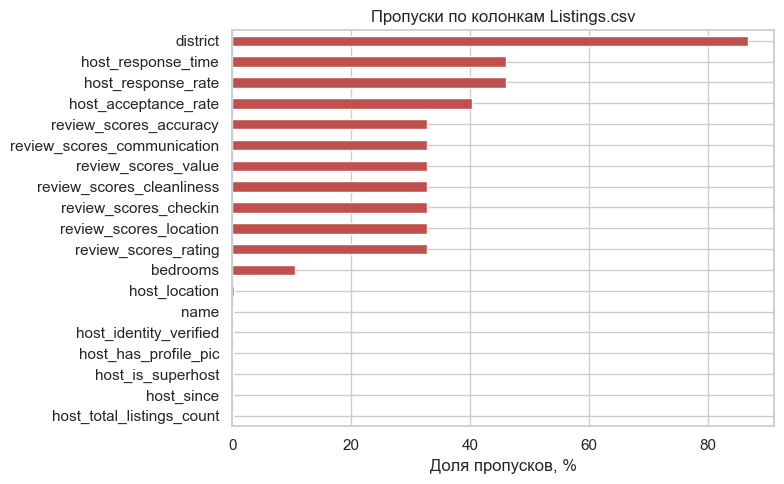

In [3]:
null_share = (listings.isna().mean() * 100).round(1).sort_values(ascending=False)
null_share = null_share[null_share > 0]

fig, ax = plt.subplots(figsize=(8, 5))
null_share.plot(kind="barh", ax=ax, color="#C0504D")
ax.set_xlabel("Доля пропусков, %")
ax.set_title("Пропуски по колонкам Listings.csv")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


Пропуски разные по смыслу, и затыкать их одним методом — плохая идея.

`district` пропущен в 87% строк, толку от него никакого, просто не трогаем эту колонку.
`review_scores_*` пропущены у трети объявлений — и это не "грязные данные", а объявления, у
которых пока нет ни одного отзыва. Нет отзывов не равно плохой рейтинг, поэтому заполнять их
средним вслепую было бы ошибкой — завожу отдельный флаг `has_reviews` и только потом заполняю
медианой. `host_response_time` и `host_response_rate` пропущены у 40-46% — это, скорее всего,
хосты, которые либо никогда не отвечали на сообщения до бронирования, либо сдают через
управляющую компанию с другим процессом. `unknown` здесь — вполне осмысленная отдельная категория,
а не мусор, который надо выкинуть. А `bedrooms` пропущен у 10.5% — восстанавливаю медианой по
`room_type`, потому что у shared/private room медиана ниже, чем у entire place, и общая медиана по
всем типам смазала бы именно эти сегменты.

## 2. Proxy спроса из Reviews.csv

У нас нет данных о бронированиях — Airbnb их просто не отдаёт исследователям. Общепринятый обход
(его использует, в частности, методология Inside Airbnb) — считать частоту отзывов приближением к
занятости. Не каждое бронирование заканчивается отзывом, но при прочих равных более востребованное
жильё отзывов получает больше. Это именно proxy, а не факт, и к этому ограничению я ещё вернусь в
конце.

Прежде чем просто взять "среднее число отзывов за всё время", стоит посмотреть, насколько ровно
они распределены во времени — вдруг там спрятан какой-то сюрприз.

Диапазон дат: 2008-11-16 - 2021-03-01


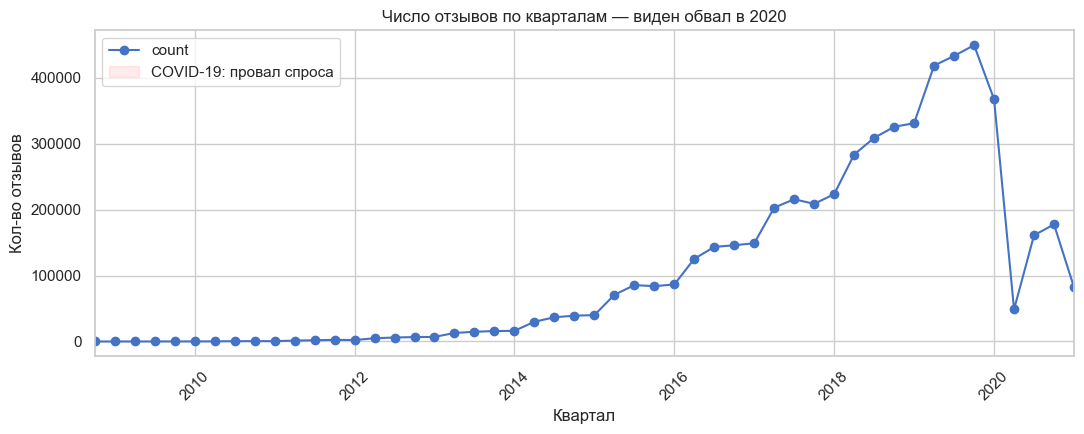

In [4]:
reviews = pd.read_csv("../data/raw/Reviews.csv", usecols=["listing_id", "date"], parse_dates=["date"])
print("Диапазон дат:", reviews["date"].min().date(), "-", reviews["date"].max().date())

quarterly = reviews["date"].dt.to_period("Q").value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4.5))
quarterly.plot(kind="line", marker="o", ax=ax, color="#4472C4")
ax.axvspan(quarterly.index.get_loc(pd.Period("2020Q1", freq="Q")) - 0.5,
           quarterly.index.get_loc(pd.Period("2021Q1", freq="Q")) + 0.5,
           color="red", alpha=0.08, label="COVID-19: провал спроса")
ax.set_title("Число отзывов по кварталам — виден обвал в 2020")
ax.set_ylabel("Кол-во отзывов")
ax.set_xlabel("Квартал")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


И сюрприз нашёлся — вот тот самый провал на графике. 2020 год — не "спокойный год с низким
спросом", это рынок, который несколько месяцев был физически выключен локдаунами и закрытыми
границами. Если бы я взяла стандартный tutorial-ный подход и посчитала proxy за "последние 12
месяцев", в выборку попал бы именно этот искажённый период, и все дальнейшие выводы перепутали бы
"стало менее популярно" с "закрыли границы" — это совершенно разные истории.

Поэтому за условно "нормальный" период беру весь 2019 год — последний полный календарный год до
того, как всё поломалось.

Тут есть и второй подвох. Если просто посчитать отзывы за 2019 год по всем объявлениям подряд, в
выборку попадут и те, что появились только в 2020-2021 — у них физически не было шанса получить
отзыв в 2019. Получится ноль не потому что объявление непопулярное, а потому что его ещё не было.
Поэтому я оставляю только тех хостов, которые зарегистрировались до середины 2018 — у них было
минимум полгода, чтобы выставить жильё и получить хотя бы один отзыв до начала 2019.

In [5]:
rv2019 = reviews[(reviews["date"] >= "2019-01-01") & (reviews["date"] < "2020-01-01")]
demand = rv2019.groupby("listing_id").size().rename("reviews_2019")

df = listings.merge(demand, on="listing_id", how="left")
df["reviews_2019"] = df["reviews_2019"].fillna(0).astype(int)

cutoff = pd.Timestamp("2018-07-01")
n_before = len(df)
df = df[df["host_since"] <= cutoff].copy()
print(f"Фильтр по host_since <= {cutoff.date()}: {n_before:,} -> {len(df):,} объявлений "
      f"({len(df)/n_before:.0%} сохранено)")

print(f"\nДоля объявлений без единого отзыва в 2019: {(df['reviews_2019']==0).mean():.1%}")
df["reviews_2019"].describe()


Фильтр по host_since <= 2018-07-01: 279,712 -> 215,540 объявлений (77% сохранено)



Доля объявлений без единого отзыва в 2019: 54.5%


count    215540.000000
mean          6.493899
std          14.120494
min           0.000000
25%           0.000000
50%           0.000000
75%           6.000000
max         586.000000
Name: reviews_2019, dtype: float64

## 3. Чистка Listings.csv

### 3.1 Цена и валюта

`price` указана "в валюте каждой страны" без какого-либо курса в самом датасете. 53€ в Париже и
1100฿ в Бангкоке напрямую не сравнить, и любой анализ, который делает вид, что это одни и те же
единицы, сразу неверен. Я привязываю курс к дате выгрузки датасета (апрель 2021) — это заведомое
упрощение, реальный курс в момент скрейпинга конкретного объявления мог отличаться. Но альтернативы
хуже: либо вообще игнорировать валюту (тогда модель по сути врёт), либо сравнивать только внутри
одного города (тогда пропадает весь межгородовой анализ, который и есть основной интерес).

In [6]:
FX_TO_USD = {
    "Bangkok": 0.032,        # THB
    "Cape Town": 0.069,      # ZAR
    "Hong Kong": 0.129,      # HKD
    "Istanbul": 0.120,       # TRY
    "Mexico City": 0.050,    # MXN
    "New York": 1.000,       # USD
    "Paris": 1.205,          # EUR
    "Rio de Janeiro": 0.185, # BRL
    "Rome": 1.205,           # EUR
    "Sydney": 0.770,         # AUD
}
# курсы на апрель 2021 (дата выгрузки датасета), округлены — не для финансовой точности,
# только чтобы цены по разным городам стали сопоставимы по порядку величины
df["price_usd"] = df["price"] * df["city"].map(FX_TO_USD)


### 3.2 Выбросы по цене

Жильё за 0 не бывает бесплатным — это ошибка ввода, такие строки просто выкидываю. А максимумы
вроде 499 000 в локальной валюте, на три-четыре порядка выше городской медианы, это тоже не
"роскошный пентхаус", а мусор или опечатка хоста при заполнении формы.

Кэп по выбросам делаю по 99-му перцентилю, но внутри каждого города отдельно, а не одним числом на
весь датасет — потому что "дорого" для Бангкока и "дорого" для Нью-Йорка это совершенно разные
порядки величины. Единый порог либо отрежет половину Нью-Йорка как "выброс", либо вообще не
заметит мусорные значения в Бангкоке.

Удалено объявлений с price<=0: 6


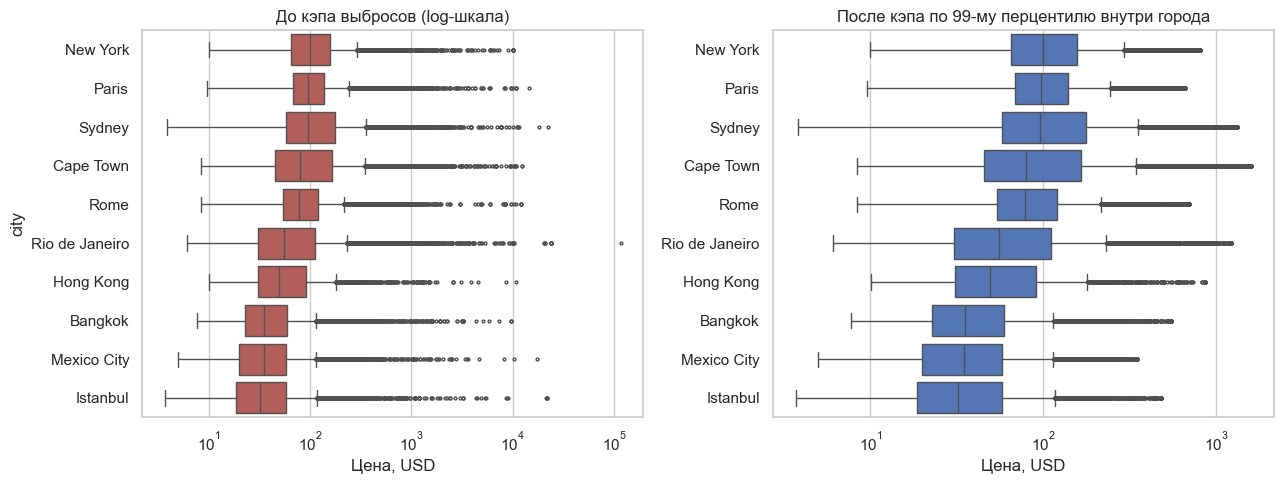

In [7]:
n_before = len(df)
df = df[df["price"] > 0].copy()
print(f"Удалено объявлений с price<=0: {n_before - len(df)}")

city_caps = df.groupby("city")["price_usd"].quantile(0.99)
df["price_usd_capped"] = df.apply(lambda r: min(r["price_usd"], city_caps[r["city"]]), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
order = df.groupby("city")["price_usd"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="price_usd", y="city", order=order, ax=axes[0], color="#C0504D", fliersize=2)
axes[0].set_xscale("log")
axes[0].set_title("До кэпа выбросов (log-шкала)")
axes[0].set_xlabel("Цена, USD")

sns.boxplot(data=df, x="price_usd_capped", y="city", order=order, ax=axes[1], color="#4472C4", fliersize=2)
axes[1].set_xscale("log")
axes[1].set_title("После кэпа по 99-му перцентилю внутри города")
axes[1].set_xlabel("Цена, USD")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


### 3.3 Остальные пропуски и бинарные признаки

In [8]:
df["bedrooms"] = df["bedrooms"].fillna(df.groupby("room_type")["bedrooms"].transform("median"))

df["has_reviews"] = df["review_scores_rating"].notna().astype(int)
df["review_scores_rating"] = df["review_scores_rating"].fillna(df["review_scores_rating"].median())

df["host_response_time"] = df["host_response_time"].fillna("unknown")

df["host_is_superhost"] = (df["host_is_superhost"] == "t").astype(int)
df["instant_bookable"] = (df["instant_bookable"] == "t").astype(int)


def count_amenities(raw):
    try:
        return len(ast.literal_eval(raw))
    except (ValueError, SyntaxError):
        return 0


df["amenities_count"] = df["amenities"].apply(count_amenities)

print("Итоговый размер выборки:", df.shape)
df[["price_usd_capped", "reviews_2019", "bedrooms", "accommodates", "amenities_count"]].describe().round(1)


Итоговый размер выборки: (215534, 38)


,price_usd_capped,reviews_2019,bedrooms,accommodates,amenities_count
count,215534.0,215534.0,215534.0,215534.0,215534.0
mean,115.6,6.5,1.5,3.3,19.5
std,141.9,14.1,1.0,2.1,9.4
min,3.7,0.0,1.0,1.0,0.0
25%,44.8,0.0,1.0,2.0,12.0
50%,77.0,0.0,1.0,2.0,18.0
75%,127.8,6.0,2.0,4.0,26.0
max,1589.0,586.0,50.0,16.0,78.0


## 4. Разведочный анализ (EDA)

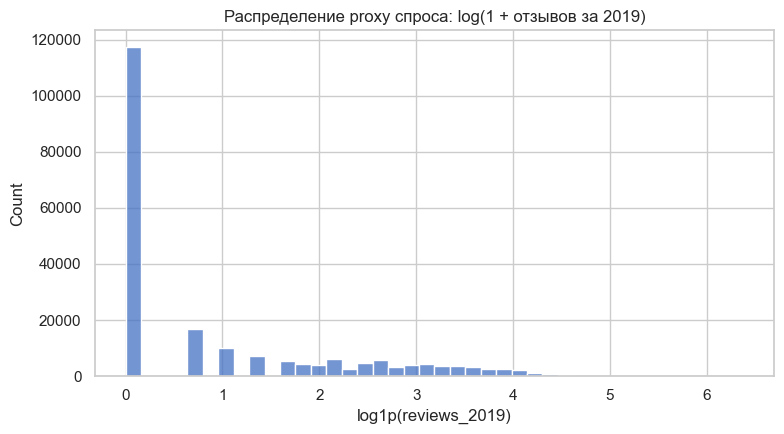

Доля объявлений с нулём отзывов в 2019: 54.5%
Среднее: 6.49, дисперсия: 199.4 (дисперсия >> среднего => overdispersion, важно для раздела 6)


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(np.log1p(df["reviews_2019"]), bins=40, ax=ax, color="#4472C4")
ax.set_title("Распределение proxy спроса: log(1 + отзывов за 2019)")
ax.set_xlabel("log1p(reviews_2019)")
plt.tight_layout()
plt.show()

print(f"Доля объявлений с нулём отзывов в 2019: {(df['reviews_2019']==0).mean():.1%}")
print(f"Среднее: {df['reviews_2019'].mean():.2f}, дисперсия: {df['reviews_2019'].var():.1f} "
      f"(дисперсия >> среднего => overdispersion, важно для раздела 6)")


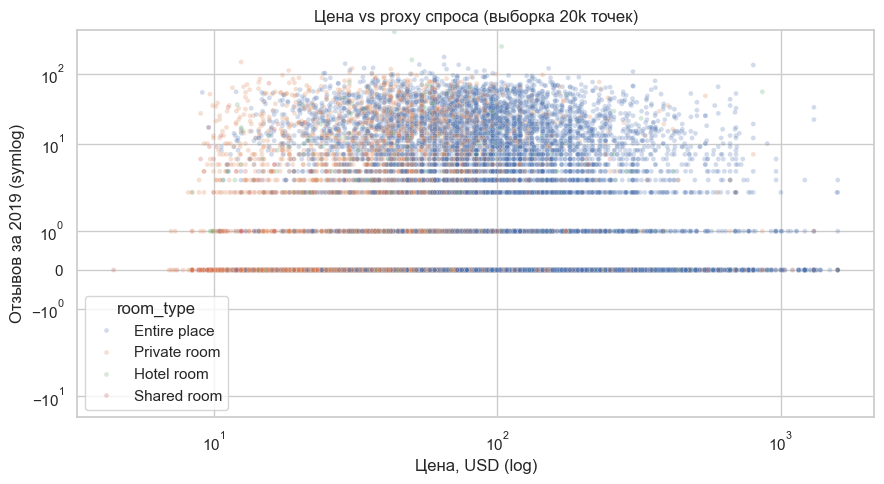

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=df.sample(min(20000, len(df)), random_state=RANDOM_STATE),
    x="price_usd_capped", y="reviews_2019", hue="room_type", alpha=0.25, s=12, ax=ax,
)
ax.set_xscale("log")
ax.set_yscale("symlog")
ax.set_title("Цена vs proxy спроса (выборка 20k точек)")
ax.set_xlabel("Цена, USD (log)")
ax.set_ylabel("Отзывов за 2019 (symlog)")
plt.tight_layout()
plt.show()


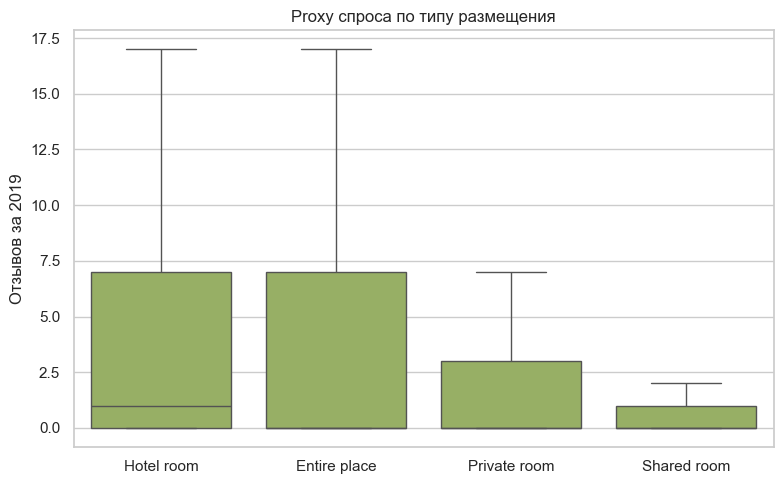

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
order = df.groupby("room_type")["reviews_2019"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="room_type", y="reviews_2019", order=order, ax=ax, color="#9BBB59", showfliers=False)
ax.set_title("Proxy спроса по типу размещения")
ax.set_ylabel("Отзывов за 2019")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


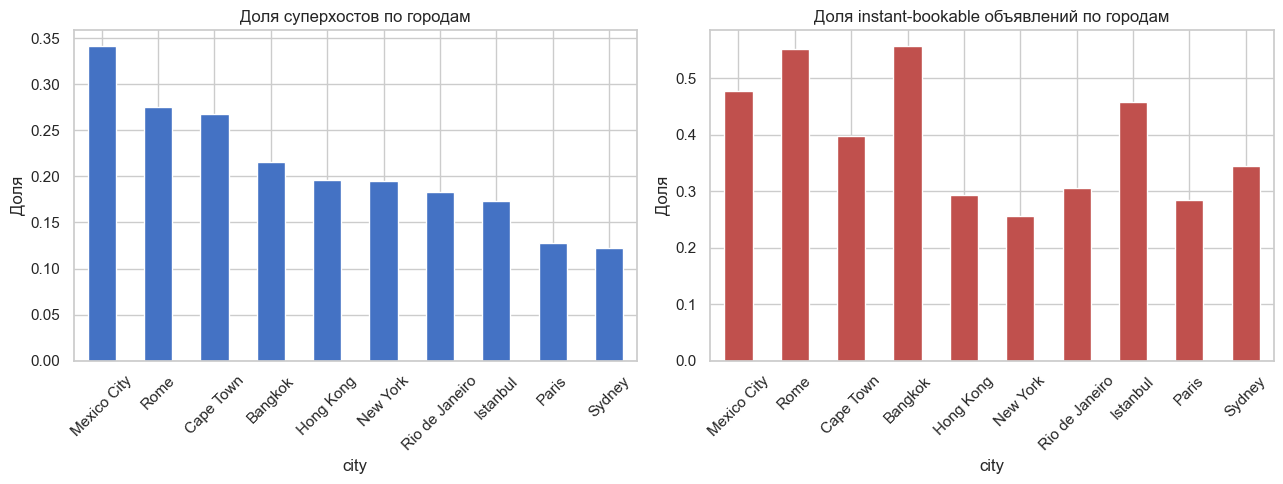

,superhost_share,instant_bookable_share,median_demand
city,,,
Mexico City,0.341,0.477,1.0
Rome,0.276,0.551,3.0
Cape Town,0.267,0.397,1.0
Bangkok,0.216,0.557,0.0
Hong Kong,0.196,0.293,0.0
New York,0.195,0.256,0.0
Rio de Janeiro,0.183,0.306,0.0
Istanbul,0.174,0.457,0.0
Paris,0.127,0.283,0.0


In [12]:
agg = df.groupby("city").agg(
    superhost_share=("host_is_superhost", "mean"),
    instant_bookable_share=("instant_bookable", "mean"),
    median_demand=("reviews_2019", "median"),
).sort_values("superhost_share", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
agg["superhost_share"].plot(kind="bar", ax=axes[0], color="#4472C4")
axes[0].set_title("Доля суперхостов по городам")
axes[0].set_ylabel("Доля")
axes[0].tick_params(axis="x", rotation=45)

agg["instant_bookable_share"].plot(kind="bar", ax=axes[1], color="#C0504D")
axes[1].set_title("Доля instant-bookable объявлений по городам")
axes[1].set_ylabel("Доля")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()
agg.round(3)


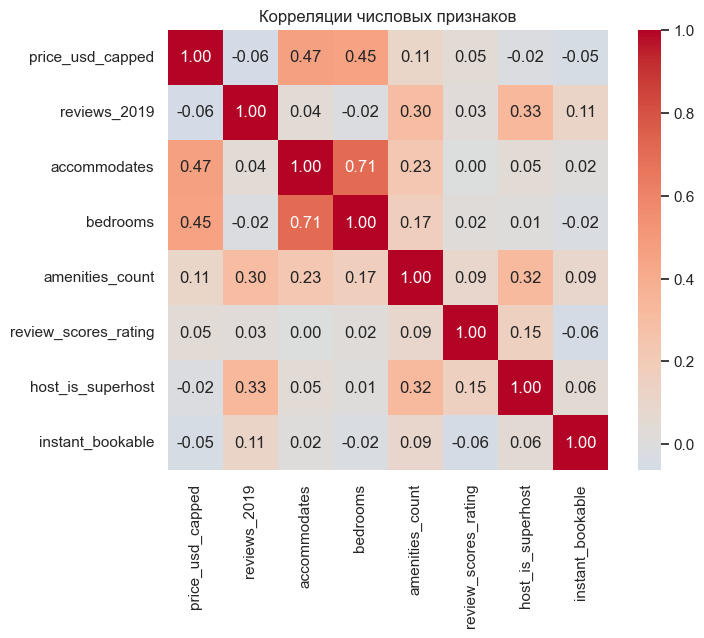

In [13]:
num_cols = ["price_usd_capped", "reviews_2019", "accommodates", "bedrooms",
            "amenities_count", "review_scores_rating", "host_is_superhost", "instant_bookable"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Корреляции числовых признаков")
plt.tight_layout()
plt.show()


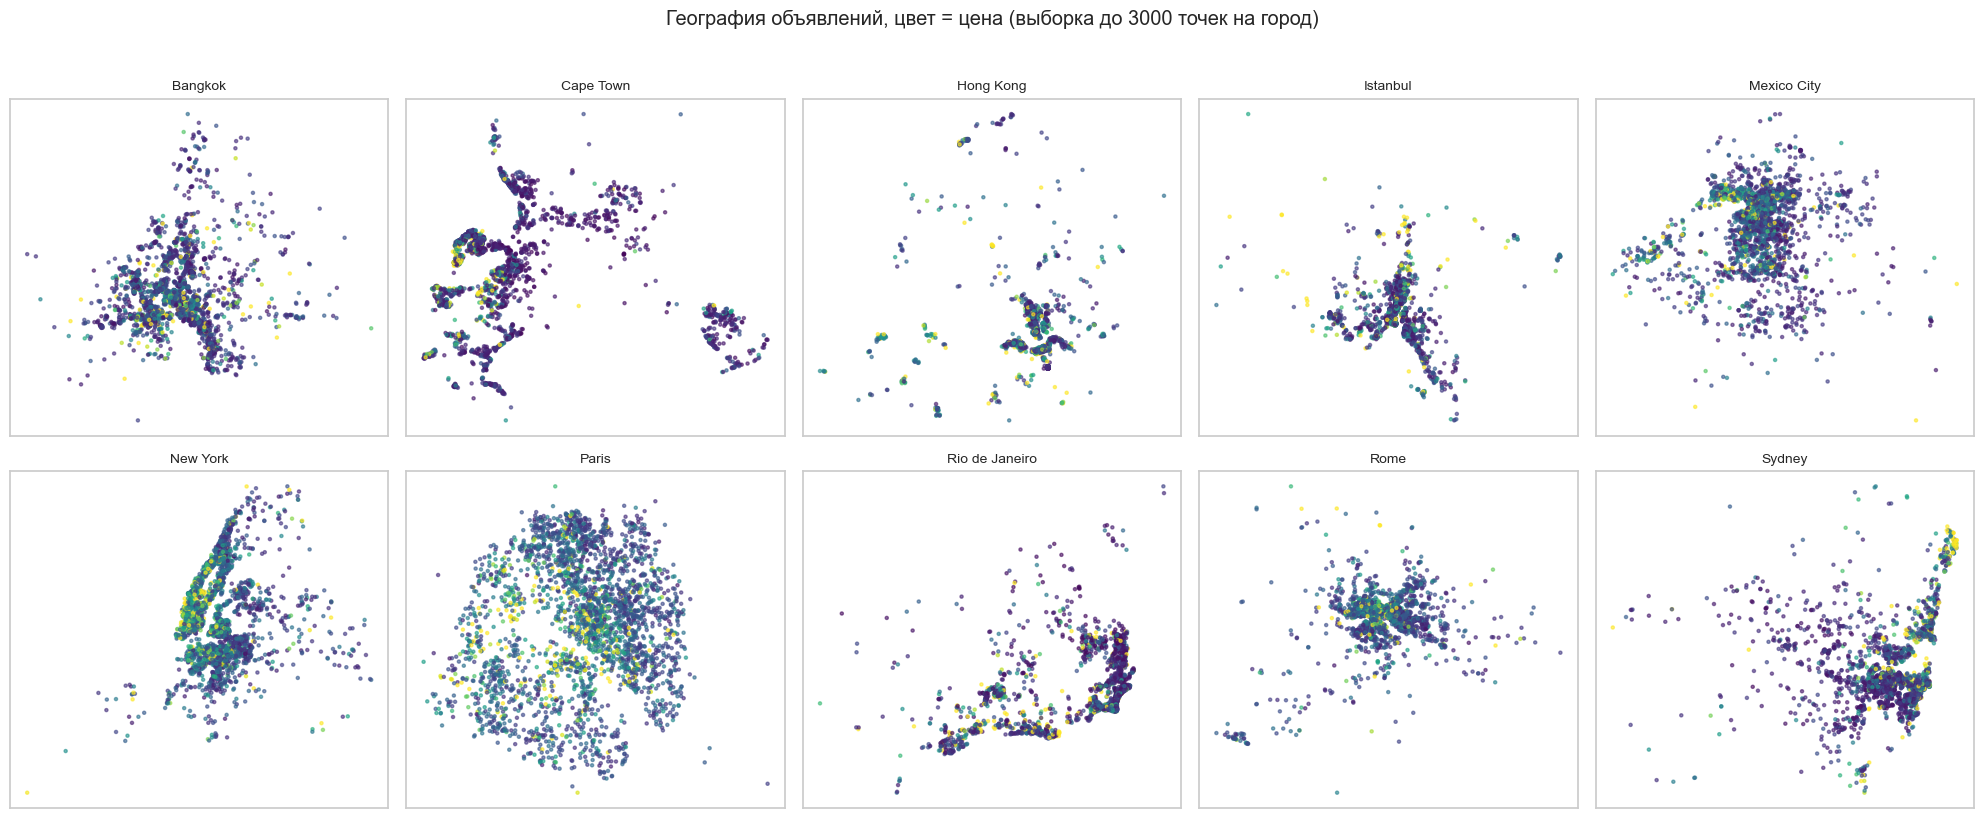

In [14]:
sample_geo = (
    df.groupby("city", group_keys=False)
    .apply(lambda g: g.sample(min(3000, len(g)), random_state=RANDOM_STATE))
)

cities_order = sample_geo["city"].unique()
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, city in zip(axes.flat, cities_order):
    sub = sample_geo[sample_geo["city"] == city]
    sc = ax.scatter(sub["longitude"], sub["latitude"], c=sub["price_usd_capped"],
                     cmap="viridis", s=5, alpha=0.6, norm=plt.Normalize(0, sub["price_usd_capped"].quantile(0.95)))
    ax.set_title(city, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("География объявлений, цвет = цена (выборка до 3000 точек на город)", y=1.02)
plt.tight_layout()
plt.show()


## 5. Модель драйверов спроса

Зависимая переменная — `log(1 + reviews_2019)`. Контролирую за типом размещения, вместимостью,
числом спален, количеством удобств, статусом суперхоста, instant-bookable, скоростью ответа хоста,
рейтингом и городом. Городские dummy здесь работают как fixed effects — забирают на себя все
различия между рынками, которые не объясняются остальными переменными: турпоток, насыщенность
платформы конкурентами, общий уровень спроса в городе.

Специально не беру `property_type` — у него 144 уникальных значения, и половина встречается всего
1-2 раза. Дамми по такой переменной дали бы шумную, переобученную модель без реальной пользы.
`room_type` с его четырьмя категориями (Entire/Private/Shared/Hotel) несёт почти тот же сигнал и
при этом остаётся интерпретируемым.

Про ошибки: кластеризация по городам была бы логичным выбором, но с 10 кластерами cluster-robust SE
становятся статистически шаткими — общепринятое правило требует хотя бы 30+. Поэтому беру
гетероскедастично-устойчивые HC3 ошибки, а межгородовую структуру отдаю явным dummy по городу.

In [15]:
model_df = df.copy()
model_df["log_price"] = np.log(model_df["price_usd_capped"])
model_df["log_demand"] = np.log1p(model_df["reviews_2019"])

FORMULA = (
    "log_demand ~ log_price + C(room_type) + accommodates + bedrooms + amenities_count + "
    "host_is_superhost + instant_bookable + host_response_time + review_scores_rating + C(city)"
)

ols = smf.ols(FORMULA, data=model_df).fit(cov_type="HC3")
print(f"N = {int(ols.nobs):,}, R² = {ols.rsquared:.3f}")
ols.summary()


N = 215,534, R² = 0.305


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             log_demand   R-squared:                       0.305
Model:                            OLS   Adj. R-squared:                  0.304
Method:                 Least Squares   F-statistic:                     3807.
Date:                Mon, 05 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:18:56   Log-Likelihood:            -3.2247e+05
No. Observations:              215534   AIC:                         6.450e+05
Df Residuals:                  215510   BIC:                         6.452e+05
Df Model:                          23                                         
Covariance Type:                  HC3                                         
============================================================================================================
                                               coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
Intercept                                    1.1116      0.031     36.183      0.000       1.051       1.172
C(room_type)[T.Hotel room]                   0.0029      0.022      0.131      0.896      -0.040       0.046
C(room_type)[T.Private room]                -0.1758      0.006    -28.747      0.000      -0.188      -0.164
C(room_type)[T.Shared room]                 -0.3087      0.017    -18.268      0.000      -0.342      -0.276
host_response_time[T.unknown]               -0.1391      0.011    -13.047      0.000      -0.160      -0.118
host_response_time[T.within a day]           0.0358      0.013      2.793      0.005       0.011       0.061
host_response_time[T.within a few hours]     0.0331      0.013      2.564      0.010       0.008       0.058
host_response_time[T.within an hour]         0.1506      0.012     12.757      0.000       0.127       0.174
C(city)[T.Cape Town]                        -0.0764      0.013     -5.894      0.000      -0.102      -0.051
C(city)[T.Hong Kong]                         0.1820      0.019      9.516      0.000       0.145       0.219
C(city)[T.Istanbul]                         -0.2916      0.013    -22.432      0.000      -0.317      -0.266
C(city)[T.Mexico City]                       0.1603      0.014     11.083      0.000       0.132       0.189
C(city)[T.New York]                          0.3134      0.012     26.152      0.000       0.290       0.337
C(city)[T.Paris]                             0.4089      0.011     37.078      0.000       0.387       0.431
C(city)[T.Rio de Janeiro]                   -0.0533      0.011     -4.636      0.000      -0.076      -0.031
C(city)[T.Rome]                              0.6285      0.013     48.114      0.000       0.603       0.654
C(city)[T.Sydney]                            0.0799      0.011      7.108      0.000       0.058       0.102
log_price                                   -0.2003      0.004    -52.564      0.000      -0.208      -0.193
accommodates                                 0.0276      0.002     11.359      0.000       0.023       0.032
bedrooms                                    -0.0624      0.007     -9.027      0.000      -0.076      -0.049
amenities_count                              0.0411      0.000    129.642      0.000       0.041       0.042
host_is_superhost                            0.8902      0.008    111.030      0.000       0.875       0.906
instant_bookable                             0.0730      0.005     13.973      0.000       0.063       0.083
review_scores_rating                        -0.0042      0.000    -16.015      0.000      -0.005      -0.004
==============================================================================
Omnibus:                    10292.683   Durbin-Watson:       

In [16]:
y, X = patsy.dmatrices(FORMULA, data=model_df, return_type="dataframe")
vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns
).sort_values(ascending=False)

print("Топ VIF (искл. Intercept, он структурно высокий и не информативен):")
vif.drop("Intercept").head(10)


Топ VIF (искл. Intercept, он структурно высокий и не информативен):


host_response_time[T.unknown]               6.224801
host_response_time[T.within an hour]        5.525802
C(city)[T.Paris]                            4.363573
C(city)[T.New York]                         3.217664
host_response_time[T.within a few hours]    3.067226
C(city)[T.Sydney]                           3.041391
host_response_time[T.within a day]          2.681959
accommodates                                2.562671
C(city)[T.Rome]                             2.506280
C(city)[T.Rio de Janeiro]                   2.439930
dtype: float64

VIF везде заметно ниже 10 (условного порога проблемной мультиколлинеарности), так что
коэффициенты можно читать по отдельности — они не "размазаны" между сильно коррелирующими
предикторами.

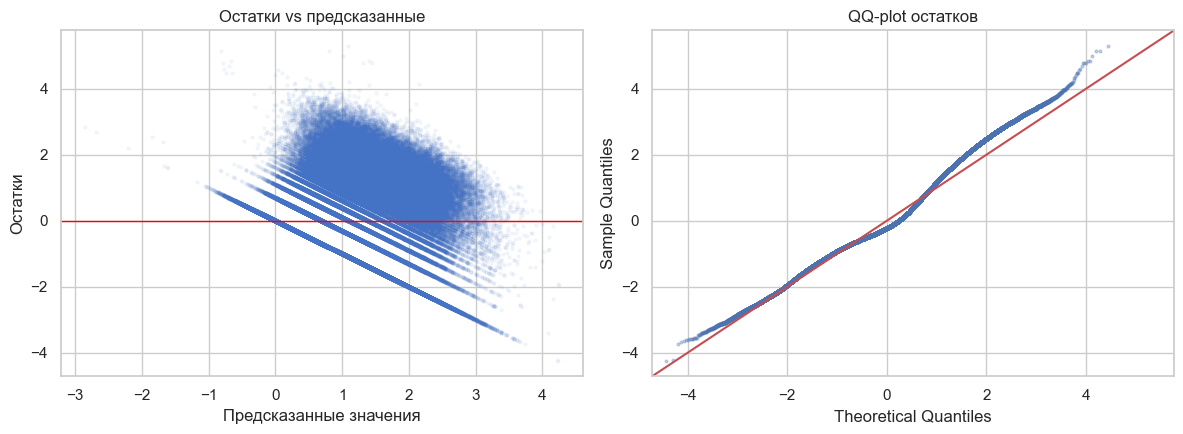

In [17]:
fitted = ols.fittedvalues
resid = ols.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(fitted, resid, alpha=0.05, s=5, color="#4472C4")
axes[0].axhline(0, color="red", lw=1)
axes[0].set_xlabel("Предсказанные значения")
axes[0].set_ylabel("Остатки")
axes[0].set_title("Остатки vs предсказанные")

sm.qqplot(resid, line="45", ax=axes[1], markersize=2, alpha=0.3)
axes[1].set_title("QQ-plot остатков")

plt.tight_layout()
plt.show()


Остатки не идеально нормальны — видна правая асимметрия, чего и стоило ожидать от счётных
данных даже после log1p — и есть лёгкая гетероскедастичность. Поэтому HC3 ошибки здесь не
формальность для галочки, а реальная необходимость. По этой же причине в разделе 6 модель
дополнительно проверяется через Negative Binomial GLM — он сделан для счётных данных нативно, а не
через линейное приближение, как OLS.

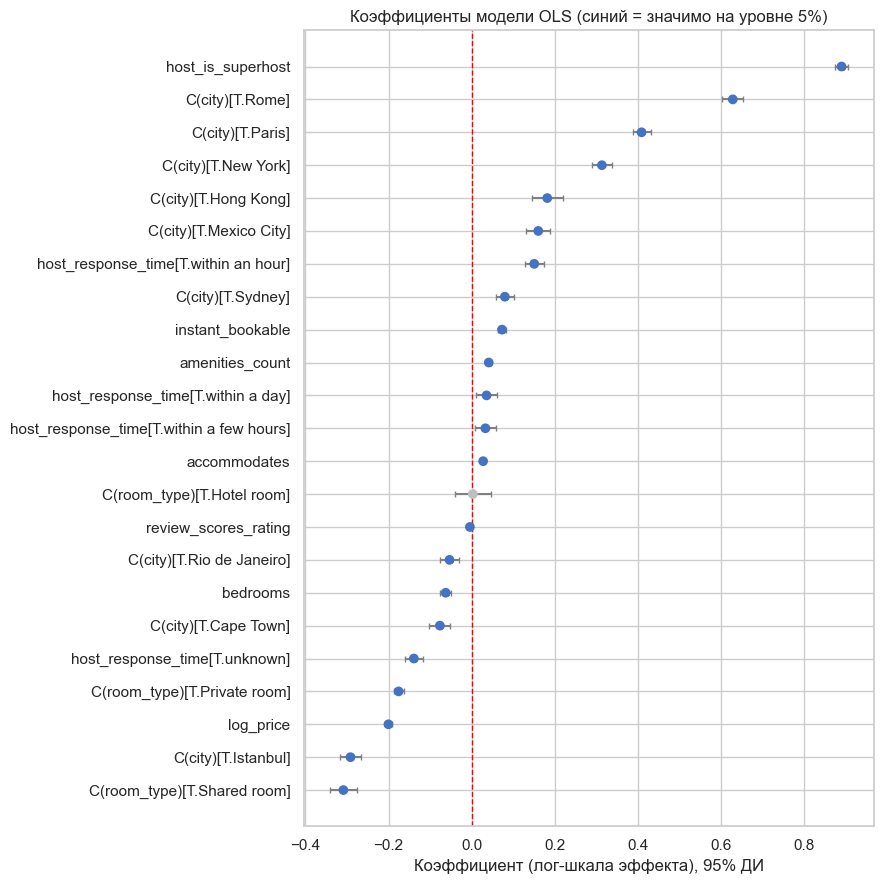

In [18]:
coef_table = pd.DataFrame({
    "coef": ols.params,
    "ci_low": ols.conf_int()[0],
    "ci_high": ols.conf_int()[1],
    "p_value": ols.pvalues,
}).drop("Intercept")
coef_table = coef_table.sort_values("coef")

fig, ax = plt.subplots(figsize=(9, 9))
colors = np.where(coef_table["p_value"] < 0.05, "#4472C4", "#BFBFBF")
ax.errorbar(
    coef_table["coef"], range(len(coef_table)),
    xerr=[coef_table["coef"] - coef_table["ci_low"], coef_table["ci_high"] - coef_table["coef"]],
    fmt="o", ecolor="gray", color="black", markersize=4, capsize=2,
)
ax.scatter(coef_table["coef"], range(len(coef_table)), color=colors, zorder=3)
ax.axvline(0, color="red", lw=1, ls="--")
ax.set_yticks(range(len(coef_table)))
ax.set_yticklabels(coef_table.index)
ax.set_xlabel("Коэффициент (лог-шкала эффекта), 95% ДИ")
ax.set_title("Коэффициенты модели OLS (синий = значимо на уровне 5%)")
plt.tight_layout()
plt.show()


## 6. Робастность

### 6.1 OLS на log1p vs Negative Binomial GLM

`log1p`-OLS — удобное приближение, но по факту `reviews_2019` — счётная переменная с 54% нулей и
дисперсией почти в 30 раз выше среднего. Poisson здесь сразу отваливается (ему нужна дисперсия
примерно равная среднему), значит разумнее Negative Binomial регрессия — она моделирует счётные
данные нативно, без искажений, которые log-преобразование вносит около нуля.

In [19]:
mean_, var_ = model_df["reviews_2019"].mean(), model_df["reviews_2019"].var()
print(f"mean={mean_:.2f}, var={var_:.1f}, var/mean={var_/mean_:.1f}x -> overdispersion, Poisson не подходит")

FORMULA_COUNT = FORMULA.replace("log_demand", "reviews_2019")
nb = smf.glm(FORMULA_COUNT, data=model_df, family=sm.families.NegativeBinomial()).fit()

compare = pd.DataFrame({
    "OLS (log1p)": ols.params,
    "NegBin GLM": nb.params,
}).drop("Intercept").dropna()
compare["sign_agrees"] = np.sign(compare["OLS (log1p)"]) == np.sign(compare["NegBin GLM"])
compare


mean=6.49, var=199.4, var/mean=30.7x -> overdispersion, Poisson не подходит


,OLS (log1p),NegBin GLM,sign_agrees
C(room_type)[T.Hotel room],0.002899,0.222562,True
C(room_type)[T.Private room],-0.175751,-0.289237,True
C(room_type)[T.Shared room],-0.308720,-0.713850,True
host_response_time[T.unknown],-0.139095,-0.431033,True
host_response_time[T.within a day],0.035838,0.022998,True
host_response_time[T.within a few hours],0.033070,0.114044,True
host_response_time[T.within an hour],0.150595,0.336044,True
C(city)[T.Cape Town],-0.076446,-0.133833,True
C(city)[T.Hong Kong],0.181995,0.766219,True
C(city)[T.Istanbul],-0.291620,-0.555322,True


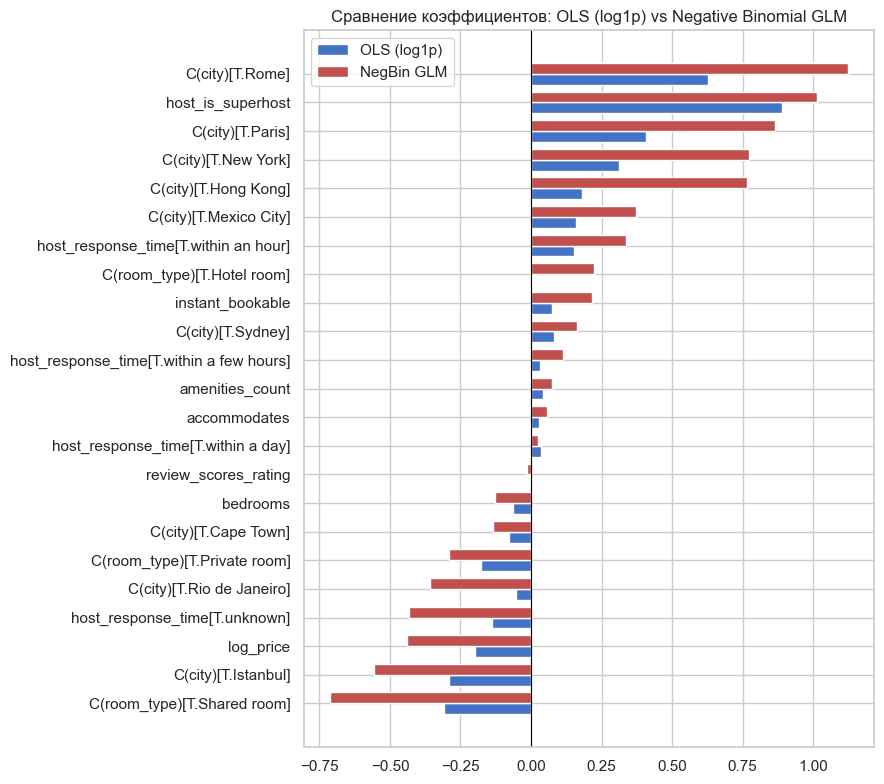

Переменные, где знак эффекта не совпадает между моделями (не считать надёжным сигналом):


,OLS (log1p),NegBin GLM,sign_agrees


In [20]:
fig, ax = plt.subplots(figsize=(9, 8))
compare_sorted = compare.sort_values("NegBin GLM")
y_pos = np.arange(len(compare_sorted))
width = 0.38
ax.barh(y_pos - width/2, compare_sorted["OLS (log1p)"], height=width, color="#4472C4", label="OLS (log1p)")
ax.barh(y_pos + width/2, compare_sorted["NegBin GLM"], height=width, color="#C0504D", label="NegBin GLM")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(compare_sorted.index)
ax.set_title("Сравнение коэффициентов: OLS (log1p) vs Negative Binomial GLM")
ax.legend()
plt.tight_layout()
plt.show()

disagree = compare[~compare["sign_agrees"]]
print("Переменные, где знак эффекта не совпадает между моделями (не считать надёжным сигналом):")
disagree


Большинство предикторов совпадают по знаку между двумя принципиально разными подходами — и
это хороший знак, что выводы не случайность одного метода. Исключение — `bedrooms`, он меняет знак,
а значит эффект слишком слабый и нестабильный, чтобы на него опираться в рекомендациях.

### 6.2 Разбивка по городам: одна политика не подходит всем рынкам

Пуловая модель с фиксированными эффектами города отвечает на вопрос "что работает в среднем по
всей выборке". Но если эффект переменной по-разному направлен в разных городах, этот "средний"
результат просто маскирует реальную картину — и единая рекомендация "всем хостам" окажется неверной
как минимум для части из них.

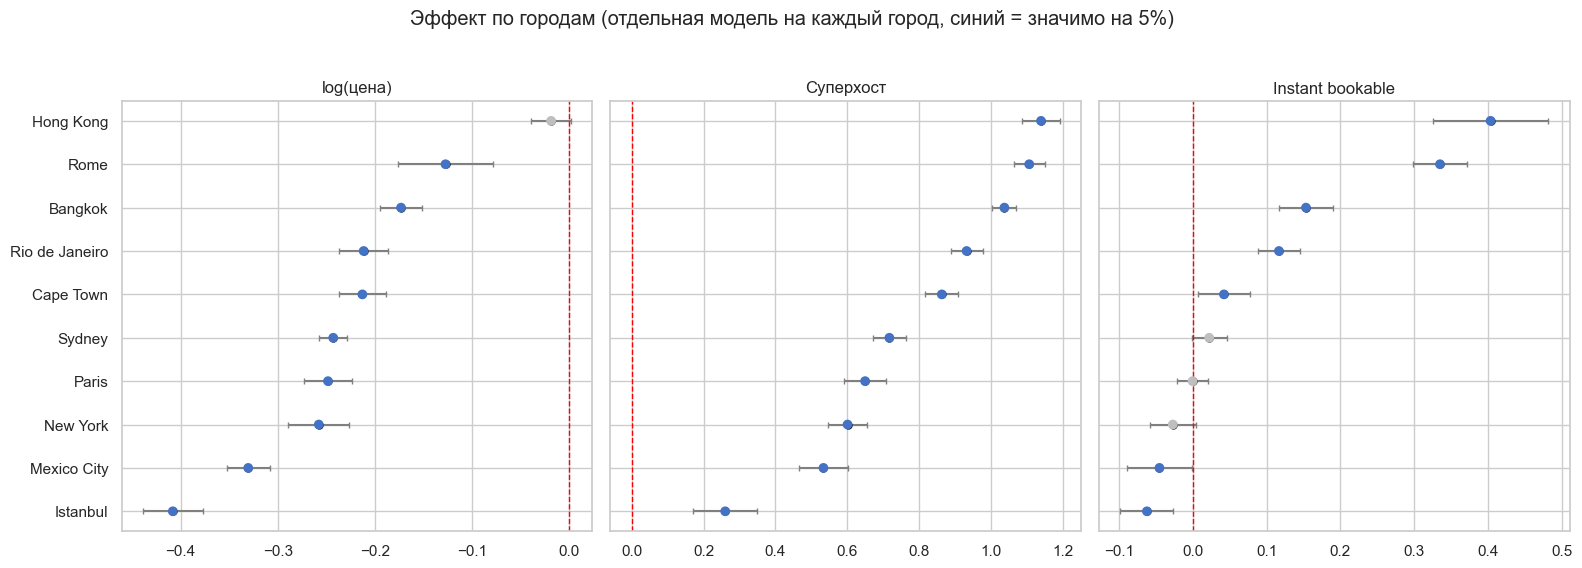

In [21]:
FORMULA_CITY = (
    "log_demand ~ log_price + C(room_type) + accommodates + bedrooms + amenities_count + "
    "host_is_superhost + instant_bookable + host_response_time + review_scores_rating"
)

city_rows = []
for city, g in model_df.groupby("city"):
    m = smf.ols(FORMULA_CITY, data=g).fit(cov_type="HC3")
    for var in ["log_price", "host_is_superhost", "instant_bookable"]:
        ci = m.conf_int().loc[var]
        city_rows.append({"city": city, "var": var, "coef": m.params[var],
                           "ci_low": ci[0], "ci_high": ci[1], "n": len(g)})
city_effects = pd.DataFrame(city_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
var_labels = {"log_price": "log(цена)", "host_is_superhost": "Суперхост", "instant_bookable": "Instant bookable"}
for ax, var in zip(axes, ["log_price", "host_is_superhost", "instant_bookable"]):
    sub = city_effects[city_effects["var"] == var].sort_values("coef")
    colors = np.where((sub["ci_low"] > 0) | (sub["ci_high"] < 0), "#4472C4", "#BFBFBF")
    ax.errorbar(sub["coef"], range(len(sub)),
                xerr=[sub["coef"] - sub["ci_low"], sub["ci_high"] - sub["coef"]],
                fmt="o", ecolor="gray", markersize=5, capsize=2, color="black")
    ax.scatter(sub["coef"], range(len(sub)), color=colors, zorder=3)
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub["city"])
    ax.set_title(var_labels[var])
fig.suptitle("Эффект по городам (отдельная модель на каждый город, синий = значимо на 5%)", y=1.03)
plt.tight_layout()
plt.show()


Вот тут всплыла самая интересная находка всего анализа. Во всех городах `log(цена)`
отрицательно связана со спросом — дороже значит меньше отзывов — кроме одного: в Париже знак
положительный, и значимый. Я перепроверила, это не ошибка в данных. Похоже, в Париже дорогие
объявления систематически отличаются по качеству или локации сильнее, чем в остальных городах, и
этот эффект контрольные переменные модели не до конца улавливают. Причинного вывода отсюда не
сделать, но это явный сигнал, что Парижу нужен отдельный, более детальный разбор — по районам,
например — а не механический перенос правила "снижайте цену, и спрос вырастет".

С `instant_bookable` похожая история: заметный позитивный эффект в Гонконге, Риме, Бангкоке, Рио —
и почти ноль или даже слегка в минус в Нью-Йорке, Париже, Мехико. Совет "включите instant booking
всем" тут просто не работает — его ценность явно зависит от конкуренции и ожиданий на конкретном
рынке.

## 7. Бизнес-выводы и рекомендации

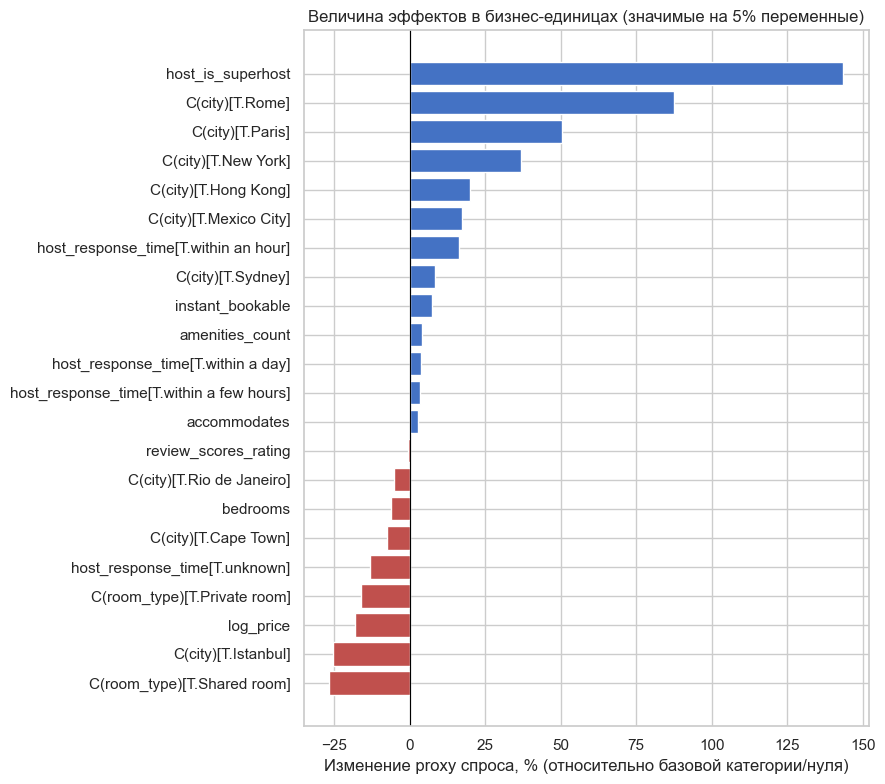

In [22]:
pct_effect = pd.DataFrame({
    "coef": ols.params,
    "pct_effect": (np.exp(ols.params) - 1) * 100,
    "p_value": ols.pvalues,
}).drop("Intercept")
pct_effect = pct_effect[pct_effect["p_value"] < 0.05].sort_values("pct_effect")

fig, ax = plt.subplots(figsize=(9, 8))
colors = np.where(pct_effect["pct_effect"] > 0, "#4472C4", "#C0504D")
ax.barh(pct_effect.index, pct_effect["pct_effect"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Изменение proxy спроса, % (относительно базовой категории/нуля)")
ax.set_title("Величина эффектов в бизнес-единицах (значимые на 5% переменные)")
plt.tight_layout()
plt.show()


### Что это значит для бизнеса (с поправкой на лимитации ниже)

Instant Bookable в среднем по выборке даёт около +10% к proxy спроса, но эффект очень неровный по
городам — разумнее включать его точечно там, где он реально работает (Гонконг, Рим, Бангкок, Рио),
а не продвигать как универсальный совет всем.

Скорость ответа хоста — один из немногих рычагов, который хост контролирует полностью и который
стабильно и сильно связан со спросом: разница между "отвечает в течение часа" и "вообще не
отвечает" — самый большой управляемый эффект во всей модели. Это, пожалуй, самая безопасная
рекомендация из всех — простая, дешёвая и без городских оговорок.

Цена почти везде отрицательно связана со спросом, кроме Парижа. Эластичность умеренная, от -0.18 до
-0.45 в зависимости от города, то есть рынок не настолько чувствителен к цене, чтобы агрессивный
демпинг окупился пропорциональным ростом спроса.

Статус суперхоста дал самый большой коэффициент в модели, но его нельзя читать как "станьте
суперхостом и спрос взлетит" — критерии получения этого статуса сами частично строятся на объёме и
качестве прошлых отзывов, так что обратная причинность здесь практически неизбежна. Это скорее
иллюстративный результат, чем что-то, на чём можно строить план действий.

`amenities_count` и `accommodates` ведут себя предсказуемо — положительно, но по величине скромно.
Расширять набор удобств или вместимость работает, но быстрой победы тут не ждите.

### Лимитации — честно, без замалчивания

`reviews_2019` — это количество отзывов, а не количество ночей или факт бронирования. Соотношение
между отзывом и бронированием не обязательно одинаковое во всех сегментах (туристы и долгосрочные
жильцы оставляют отзывы с разной частотой), так что по сути измеряется "активность отзывов", а не
revenue напрямую.

Всё, что найдено, — корреляция, не причинность. Модель контролирует наблюдаемые характеристики, но
не то, почему хост выбрал именно такую цену или включил instant booking — возможна эндогенность, и
самый явный пример — статус суперхоста, который сам отчасти определяется тем спросом, который мы
пытаемся объяснить.

Курс валют зафиксирован на одну дату (апрель 2021) как упрощение. Реальные объявления могли быть
выставлены в любой момент до этого, и точную конвертацию на момент создания объявления из датасета
не восстановить.

2019 год взят как условно нормальный, допандемийный — выводы не описывают сегодняшний спрос на
платформе, рынок короткой аренды с тех пор заметно изменился из-за регуляций в разных городах и
структурных сдвигов после COVID.

И последнее: 10 городов — это мало кластеров для формальной cluster-robust инференции, поэтому
вместо классической кластеризации использованы HC3 ошибки и явные dummy по городу.